<a href="https://colab.research.google.com/github/thearyt572-jpg/Artifical-Intelligent---TP-class/blob/main/TP4_Optimization_RITH_THEARY.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP4: Training with SGD, Mini-batches and Momentum

A typical training pipeline:
* Prepare the dataset: split it, normalize it to zero mean and unit variance.
* Define the model, the loss function and the optimizer; initialize the parameters.
* Loop until a stopping criterion:
  * take a mini-batch of data;
  * compute the forward pass;
  * compute the loss on the predictions and the labels;
  * update the parameters with the optimizer.
* Tune the hyperparameters: learning rate, batch size, number of epochs, optimizer.

PyTorch gives one object for each part (`DataLoader`, `nn.Module`, loss, `optim`), so we can change one part and keep the others.

**This TP**
1. **Follow along (Parts 0–4).** On a toy problem, train the same model three ways: SGD with **1 example per update**, **mini-batch** SGD, and mini-batch SGD with **momentum**. Then compare the three on one figure. Part 4 prepares MNIST for the exercises.
2. **Exercises (to submit).** On MNIST, and optionally CIFAR-10: experiment with the learning rate, the batch size, momentum and other optimizers, learning rate schedules and batch normalization. After each experiment, write what you observe and explain it in the cell.

**Runtime:** Colab with a GPU (Runtime → Change runtime type → T4 GPU).

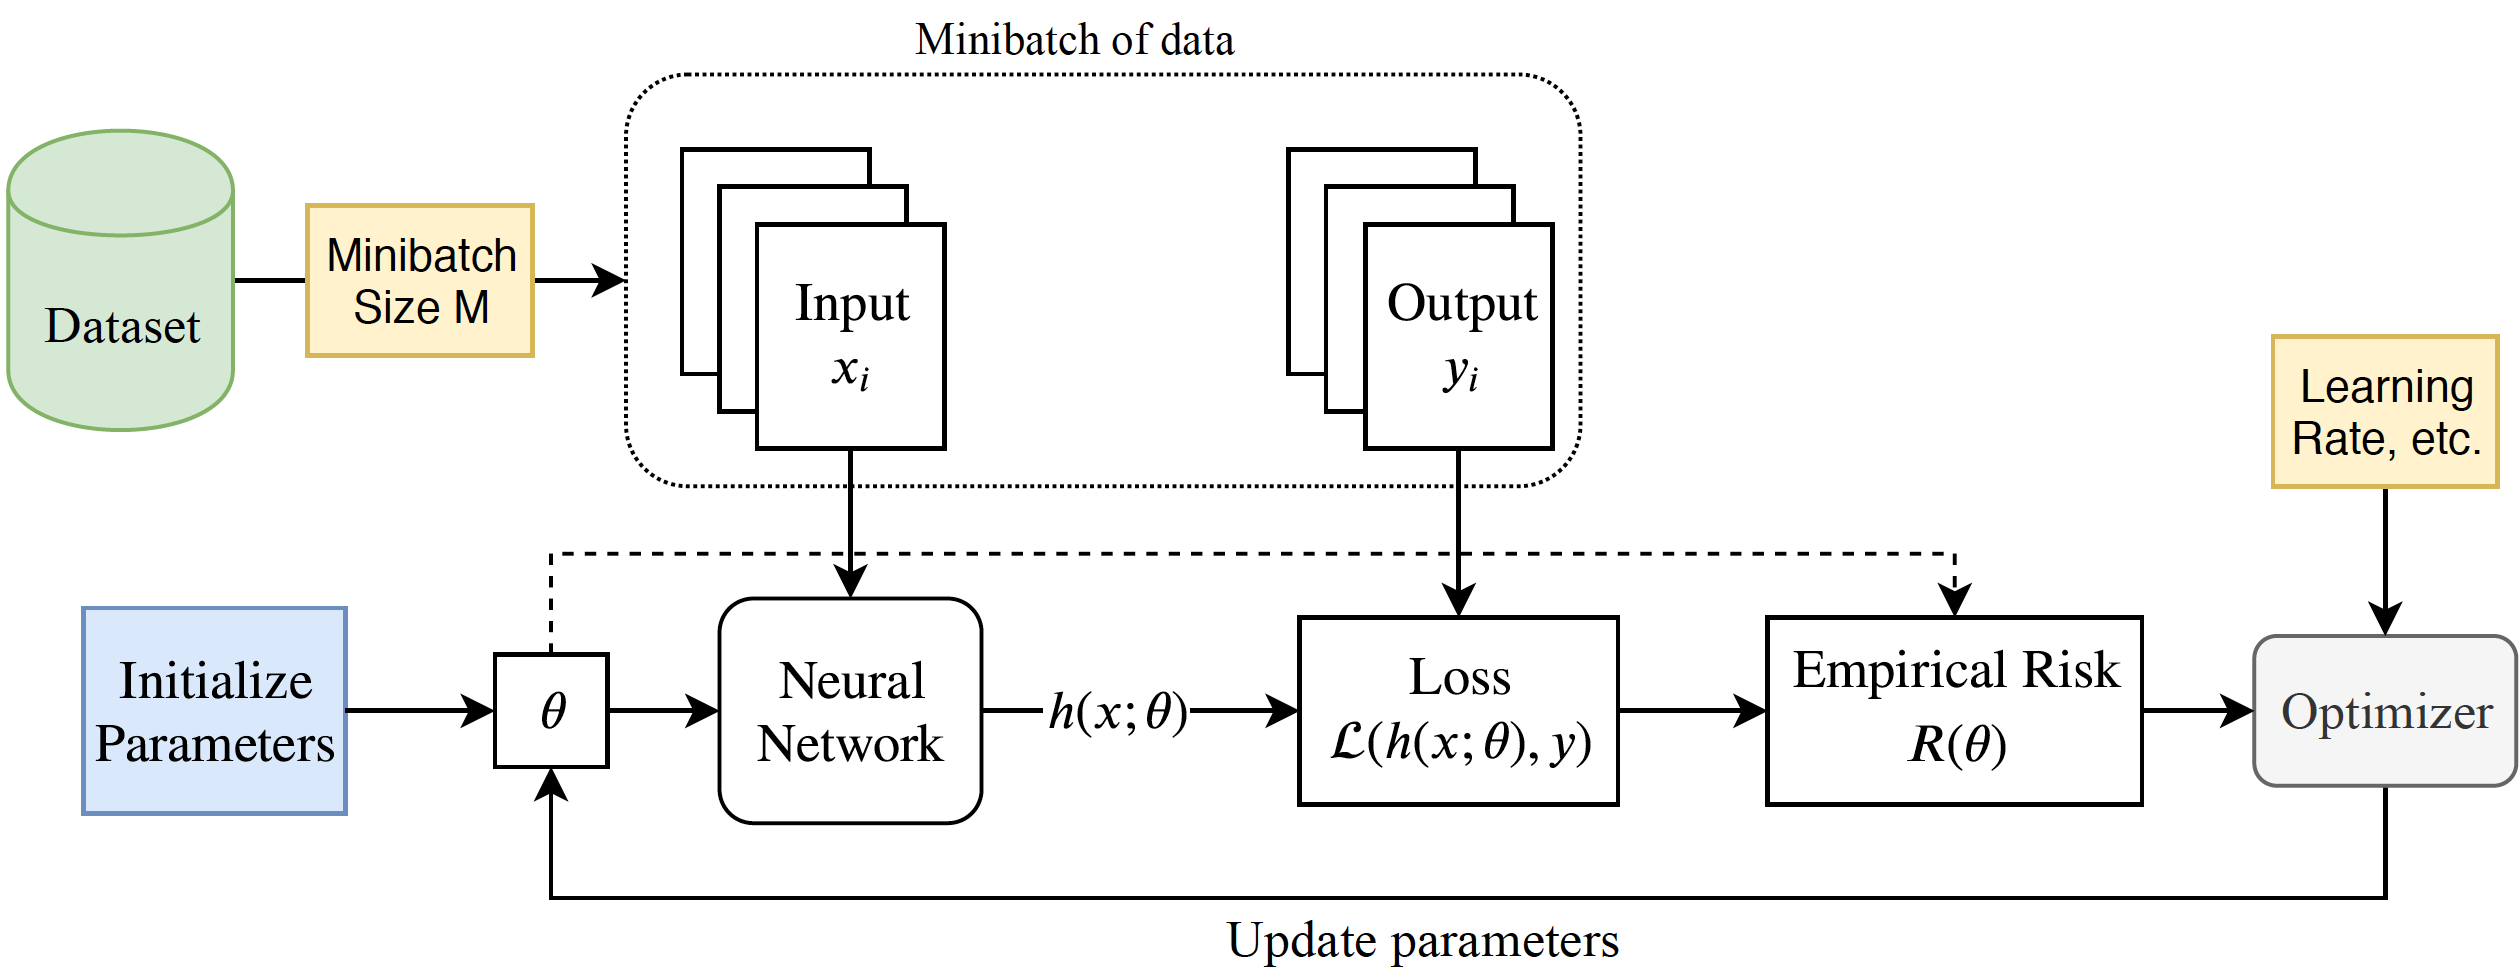

## 0 · Setup

In [46]:
import math, time, random
import numpy as np
import torch
from torch import nn, optim
from torch.utils.data import TensorDataset, DataLoader
from torchvision import datasets
import matplotlib.pyplot as plt

SEED = 1234
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.14.1+cu130 | device: cuda


## 1 · A toy problem: linear regression

1,000 points $(x, y)$ with $y = 3x + 2 + \text{noise}$ and $x$ between 0 and 5. The model is one linear unit, $\hat y = w x + b$ (`nn.Linear(1, 1)`), trained with the mean squared error
$$J(w, b) = \frac{1}{m}\sum_{i=1}^{m}\big(w x^{(i)} + b - y^{(i)}\big)^2 .$$
With only two parameters we can draw every step of the optimizer on the contour plot of $J$.

Inputs and targets are tensors of shape $(m, 1)$: one example per row.

least squares: w = 2.989, b = 2.062, J = 0.9493


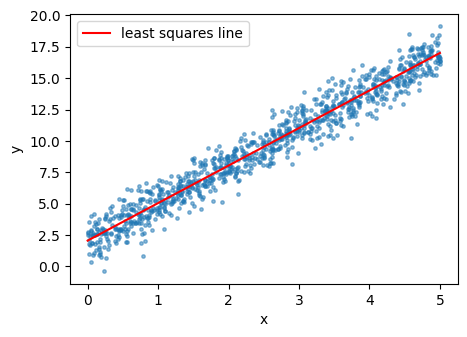

In [47]:
m = 1000
gen = torch.Generator().manual_seed(0)
x_toy = 5 * torch.rand(m, 1, generator=gen)
y_toy = 3 * x_toy + 2 + torch.randn(m, 1, generator=gen)

# the best possible (w, b), by least squares, to measure how far each run is from it
A = torch.cat([x_toy, torch.ones(m, 1)], dim=1)
w_best, b_best = torch.linalg.lstsq(A, y_toy).solution.flatten().tolist()
J_best = ((w_best * x_toy + b_best - y_toy) ** 2).mean().item()
print(f"least squares: w = {w_best:.3f}, b = {b_best:.3f}, J = {J_best:.4f}")

plt.figure(figsize=(5, 3.5))
plt.scatter(x_toy, y_toy, s=6, alpha=0.5)
plt.plot([0, 5], [b_best, 5 * w_best + b_best], "r", label="least squares line")
plt.xlabel("x"); plt.ylabel("y"); plt.legend(); plt.show()

Every run starts from the same point, $w = 0$, $b = 8$, uses the same learning rate $\alpha = 0.01$ and trains for 20 epochs. Only the **batch size** and **momentum** change.

`train_toy` is the PyTorch training loop. After every update it records:
- the loss $J(w, b)$ on **all** 1,000 points (to compare runs fairly, even when they update on different numbers of examples);
- the values of $w$ and $b$ (to draw the path).

In [48]:
def full_loss(model):
    with torch.no_grad():
        return ((model(x_toy) - y_toy) ** 2).mean().item()

def train_toy(batch_size, lr=0.01, momentum=0.0, epochs=20, seed=0):
    model = nn.Linear(1, 1)
    with torch.no_grad():                              # same starting point for every run
        model.weight.fill_(0.0)
        model.bias.fill_(8.0)
    loss_fn = nn.MSELoss()
    optimizer = optim.SGD(model.parameters(), lr=lr, momentum=momentum)
    loader = DataLoader(TensorDataset(x_toy, y_toy), batch_size=batch_size, shuffle=True,
                        generator=torch.Generator().manual_seed(seed))

    hist = {"loss": [full_loss(model)], "w": [0.0], "b": [8.0], "epoch_loss": [full_loss(model)], "time": 0.0}
    for epoch in range(epochs):
        for x_t, y_t in loader:
            start = time.perf_counter()
            loss = loss_fn(model(x_t), y_t)            # forward pass and loss on the mini-batch
            optimizer.zero_grad()
            loss.backward()                            # backpropagation
            optimizer.step()                           # update w and b
            hist["time"] += time.perf_counter() - start
            hist["loss"].append(full_loss(model))      # record (not part of training)
            hist["w"].append(model.weight.item()); hist["b"].append(model.bias.item())
        hist["epoch_loss"].append(full_loss(model))
        if (epoch + 1) % 1 == 0:
            print(f"epoch {epoch + 1:2d} | J = {hist['epoch_loss'][-1]:.4f} | w = {model.weight.item():.3f}, b = {model.bias.item():.3f}")
    print(f"updates: {len(hist['loss']) - 1} | training time: {hist['time']:.2f} s")
    return hist

## 2 · Three ways to train

### 2.1 SGD with one example per update
`batch_size=1`: each update uses the gradient of **one** randomly chosen example. One epoch = 1,000 updates.

In [49]:
hist_sgd = train_toy(batch_size=1)

epoch  1 | J = 1.0230 | w = 2.891, b = 2.075
epoch  2 | J = 0.9702 | w = 3.026, b = 2.103
epoch  3 | J = 0.9785 | w = 3.060, b = 2.020
epoch  4 | J = 1.0928 | w = 3.165, b = 1.898
epoch  5 | J = 0.9849 | w = 3.022, b = 2.163
epoch  6 | J = 0.9735 | w = 3.021, b = 2.131
epoch  7 | J = 1.0184 | w = 2.892, b = 2.084
epoch  8 | J = 0.9566 | w = 3.013, b = 2.081
epoch  9 | J = 1.0841 | w = 2.855, b = 2.087
epoch 10 | J = 0.9812 | w = 3.055, b = 2.048
epoch 11 | J = 1.0366 | w = 3.056, b = 2.174
epoch 12 | J = 1.0330 | w = 3.068, b = 2.130
epoch 13 | J = 1.0759 | w = 3.090, b = 2.132
epoch 14 | J = 1.0242 | w = 2.915, b = 1.997
epoch 15 | J = 1.0084 | w = 2.887, b = 2.127
epoch 16 | J = 1.3911 | w = 2.786, b = 1.976
epoch 17 | J = 1.0375 | w = 2.872, b = 2.112
epoch 18 | J = 0.9864 | w = 3.090, b = 1.933
epoch 19 | J = 0.9582 | w = 3.017, b = 2.076
epoch 20 | J = 0.9500 | w = 2.972, b = 2.112
updates: 20000 | training time: 8.12 s


The loss gets close to its minimum ($J \approx 1.05$, the noise level) within the first epoch, but then it **does not settle**: each update follows a single example, so $w$ and $b$ keep jumping around the minimum.

### 2.2 Mini-batch SGD
`batch_size=32`: each update uses the average gradient of 32 examples. One epoch = 32 updates (the last mini-batch has 8 examples).

In [50]:
hist_mb = train_toy(batch_size=32)

epoch  1 | J = 8.3765 | w = 1.290, b = 7.434
epoch  2 | J = 6.4393 | w = 1.595, b = 6.707
epoch  3 | J = 4.9947 | w = 1.744, b = 6.033
epoch  4 | J = 3.9405 | w = 1.904, b = 5.466
epoch  5 | J = 3.1727 | w = 2.041, b = 4.983
epoch  6 | J = 2.5936 | w = 2.240, b = 4.604
epoch  7 | J = 2.1565 | w = 2.310, b = 4.232
epoch  8 | J = 1.8781 | w = 2.474, b = 3.953
epoch  9 | J = 1.6184 | w = 2.477, b = 3.674
epoch 10 | J = 1.4506 | w = 2.593, b = 3.461
epoch 11 | J = 1.3177 | w = 2.637, b = 3.265
epoch 12 | J = 1.2207 | w = 2.670, b = 3.093
epoch 13 | J = 1.1542 | w = 2.734, b = 2.958
epoch 14 | J = 1.1020 | w = 2.739, b = 2.826
epoch 15 | J = 1.0610 | w = 2.787, b = 2.724
epoch 16 | J = 1.0336 | w = 2.810, b = 2.636
epoch 17 | J = 1.0126 | w = 2.829, b = 2.556
epoch 18 | J = 0.9964 | w = 2.867, b = 2.491
epoch 19 | J = 0.9886 | w = 2.900, b = 2.435
epoch 20 | J = 0.9762 | w = 2.906, b = 2.381
updates: 640 | training time: 0.33 s


The updates are much less noisy, and each one is computed for 32 examples at once (vectorized). But with the same $\alpha$ there are 32 times fewer updates per epoch, so after 20 epochs the run is still on its way to the minimum.

### 2.3 Mini-batch SGD with momentum
Same mini-batches, with `momentum=0.9`. PyTorch’s update is
$$\mathbf{v} \leftarrow 0.9\,\mathbf{v} + \nabla J^{\{t\}}, \qquad \theta \leftarrow \theta - \alpha\,\mathbf{v}.$$

In [51]:
hist_mom = train_toy(batch_size=64, momentum=0.9)

epoch  1 | J = 6.1264 | w = 1.434, b = 5.922
epoch  2 | J = 1.4561 | w = 2.634, b = 3.438
epoch  3 | J = 1.0152 | w = 3.024, b = 2.225
epoch  4 | J = 0.9865 | w = 3.092, b = 1.923
epoch  5 | J = 0.9673 | w = 3.071, b = 1.918
epoch  6 | J = 0.9700 | w = 3.055, b = 2.005
epoch  7 | J = 0.9650 | w = 3.032, b = 2.063
epoch  8 | J = 1.0744 | w = 3.099, b = 2.102
epoch  9 | J = 0.9555 | w = 3.013, b = 2.073
epoch 10 | J = 0.9531 | w = 2.964, b = 2.075
epoch 11 | J = 0.9698 | w = 2.941, b = 2.056
epoch 12 | J = 0.9842 | w = 2.928, b = 2.052
epoch 13 | J = 0.9596 | w = 2.954, b = 2.062
epoch 14 | J = 0.9543 | w = 3.008, b = 2.081
epoch 15 | J = 0.9756 | w = 3.041, b = 2.074
epoch 16 | J = 0.9545 | w = 3.009, b = 2.079
epoch 17 | J = 0.9496 | w = 2.985, b = 2.056
epoch 18 | J = 0.9775 | w = 3.036, b = 2.098
epoch 19 | J = 0.9519 | w = 3.004, b = 2.070
epoch 20 | J = 0.9505 | w = 3.005, b = 2.048
updates: 320 | training time: 0.17 s


## 3 · Comparing the three runs
Three views of the same three runs:
1. the loss after each **epoch** (above its minimum $J_{\text{best}}$, on a log scale);
2. the loss after each **update**;
3. the **path** of $(w, b)$ on the contours of $J$.

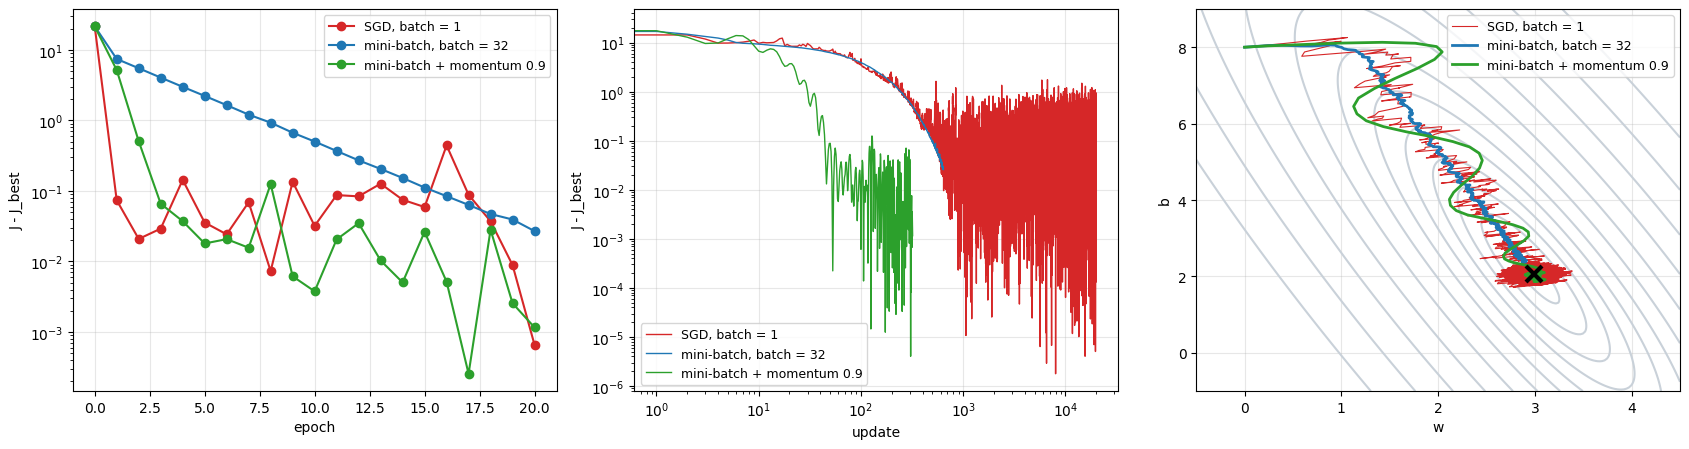

SGD, batch = 1               updates:  20000 | time: 8.12 s | final J - J_best: 0.0007
mini-batch, batch = 32       updates:    640 | time: 0.33 s | final J - J_best: 0.0269
mini-batch + momentum 0.9    updates:    320 | time: 0.17 s | final J - J_best: 0.0012


In [52]:
runs = {"SGD, batch = 1": hist_sgd, "mini-batch, batch = 32": hist_mb, "mini-batch + momentum 0.9": hist_mom}
colors = ["tab:red", "tab:blue", "tab:green"]

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
for (label, h), c in zip(runs.items(), colors):
    ax[0].plot(np.array(h["epoch_loss"]) - J_best + 1e-6, "o-", color=c, label=label)
    ax[1].plot(np.array(h["loss"]) - J_best + 1e-6, color=c, lw=1, label=label)
ax[0].set_yscale("log"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("J - J_best")
ax[1].set_xscale("log"); ax[1].set_yscale("log"); ax[1].set_xlabel("update"); ax[1].set_ylabel("J - J_best")

W, B = torch.meshgrid(torch.linspace(-0.5, 4.5, 200), torch.linspace(-1, 9, 200), indexing="xy")
# J(w, b) on the grid, from the averages of x^2, x, xy, y, y^2 (expand the square)
Ex2, Ex, Exy, Ey, Ey2 = [t.mean().item() for t in (x_toy ** 2, x_toy, x_toy * y_toy, y_toy, y_toy ** 2)]
Jgrid = W ** 2 * Ex2 + 2 * W * B * Ex + B ** 2 - 2 * W * Exy - 2 * B * Ey + Ey2
ax[2].contour(W, B, Jgrid, levels=np.geomspace(1.1, 60, 12), colors="#C9D1D9")
for (label, h), c in zip(runs.items(), colors):
    ax[2].plot(h["w"], h["b"], color=c, lw=0.8 if "= 1" in label else 2, label=label)
ax[2].plot(w_best, b_best, "kx", ms=12, mew=3)
ax[2].set_xlabel("w"); ax[2].set_ylabel("b")
for a in ax:
    a.grid(alpha=0.3); a.legend(fontsize=9)
plt.tight_layout(); plt.show()

for label, h in runs.items():
    print(f"{label:28s} updates: {len(h['loss']) - 1:6d} | time: {h['time']:.2f} s | final J - J_best: {h['epoch_loss'][-1] - J_best:.4f}")

**What the figure shows**
- **SGD, batch = 1** (red): the most updates per epoch, so the fastest progress per epoch at first. Its path is a cloud of jumps: it reaches the minimum region quickly and then wanders around it. It also takes the most time: 1,000 small updates per epoch, one Python loop iteration each.
- **Mini-batch, batch = 32** (blue): a smooth path, with few updates per epoch. The contours are long, narrow ellipses (a **ravine**: $w$ and $b$ are strongly correlated because $x$ is not centered), and with $\alpha = 0.01$ the run moves slowly along the long direction.
- **Mini-batch + momentum** (green): the same number of updates as blue, but the velocity accumulates the steps along the ravine, so it reaches the minimum much sooner.

The run with batch = 1 would need a **decaying** learning rate to settle, and the run with batch = 32 a larger one or momentum: the batch size, the learning rate and momentum have to be chosen together. The exercises explore this on real data.

## 4 · Tools for the exercises: MNIST

### 4.1 The data
MNIST: 28 × 28 grayscale images of handwritten digits, 10 classes. We keep 54,000 images for training, 6,000 for validation, and the 10,000 test images for the very end. Each image is flattened to a row of 784 values and normalized with the mean and standard deviation of the training pixels. The tensors are prepared once, so the `DataLoader` is fast.

train (54000, 784) | val (6000, 784) | test (10000, 784)


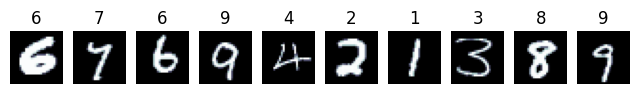

In [53]:
train_full = datasets.MNIST(root="data", train=True, download=True)
test_full = datasets.MNIST(root="data", train=False, download=True)

perm = torch.randperm(60000, generator=torch.Generator().manual_seed(42))
pixels = train_full.data[perm[:54000]].float() / 255
mean, std = pixels.mean(), pixels.std()                  # training statistics only

def prep(images):
    return ((images.float() / 255 - mean) / std).reshape(len(images), -1)   # (m, 784)

X_all, y_all = prep(train_full.data), train_full.targets
X_train, y_train = X_all[perm[:54000]], y_all[perm[:54000]]
X_val, y_val = X_all[perm[54000:]], y_all[perm[54000:]]
X_test, y_test = prep(test_full.data), test_full.targets
print("train", tuple(X_train.shape), "| val", tuple(X_val.shape), "| test", tuple(X_test.shape))

plt.figure(figsize=(8, 2.4))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(X_train[i].reshape(28, 28), cmap="bone"); plt.title(int(y_train[i])); plt.axis("off")
plt.show()

def make_loader(batch_size=64, n_train=None, seed=0):
    # mini-batches of the first n_train training examples (all of them if n_train is None)
    X, y = (X_train, y_train) if n_train is None else (X_train[:n_train], y_train[:n_train])
    return DataLoader(TensorDataset(X, y), batch_size=batch_size, shuffle=True,
                      generator=torch.Generator().manual_seed(seed))

### 4.2 The model
A multilayer perceptron 784 → 128 → 100 → 10 with ReLU, returning logits. With `batch_norm=True`, an `nn.BatchNorm1d` layer comes after each hidden linear layer, before the ReLU, and the linear layer has no bias (batch norm’s $\beta$ replaces it). `make_model(seed)` gives the same initial weights for the same seed, so that two runs differ only by what you change.

In [54]:
class MLP(nn.Module):
    def __init__(self, n_in=784, hidden=(128, 100), n_out=10, batch_norm=False):
        super().__init__()
        layers = []
        for h in hidden:
            layers.append(nn.Linear(n_in, h, bias=not batch_norm))
            if batch_norm:
                layers.append(nn.BatchNorm1d(h))
            layers.append(nn.ReLU())
            n_in = h
        layers.append(nn.Linear(n_in, n_out))
        self.layers = nn.Sequential(*layers)

    def forward(self, x):
        return self.layers(x)

def make_model(seed=0, **kwargs):
    torch.manual_seed(seed)
    return MLP(**kwargs).to(device)

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print(make_model())
print(f"{count_parameters(make_model()):,} parameters | with batch norm: {count_parameters(make_model(batch_norm=True)):,}")

MLP(
  (layers): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=100, bias=True)
    (3): ReLU()
    (4): Linear(in_features=100, out_features=10, bias=True)
  )
)
114,390 parameters | with batch norm: 114,618


### 4.3 Training and evaluation
- `evaluate(model, X, y)` returns the loss and the accuracy (%) on a dataset, in evaluation mode.
- `fit(model, optimizer, loader, epochs, scheduler=None)` trains with mini-batches and returns a history: the loss of every update (`"step_loss"`), and per epoch the training loss, the validation loss and accuracy, the learning rate and the elapsed time. If the loss becomes `nan` or `inf`, the run has **diverged**: `fit` stops and sets `"diverged"` to `True`. A scheduler, if given, is stepped once per epoch.
- `plot_history({label: history, ...})` plots the smoothed loss of every update and the validation accuracy per epoch.

In [55]:
def evaluate(model, X, y, batch_size=2000):
    model.eval()
    loss_fn = nn.CrossEntropyLoss(reduction="sum")
    total, correct = 0.0, 0
    with torch.inference_mode():
        for i in range(0, len(X), batch_size):
            xb, yb = X[i:i + batch_size].to(device), y[i:i + batch_size].to(device)
            logits = model(xb)
            total += loss_fn(logits, yb).item()
            correct += (logits.argmax(dim=1) == yb).sum().item()
    return total / len(X), 100 * correct / len(X)

def fit(model, optimizer, loader, epochs, scheduler=None, verbose=True):
    loss_fn = nn.CrossEntropyLoss()
    hist = {"step_loss": [], "train_loss": [], "val_loss": [], "val_acc": [], "lr": [], "time": [], "diverged": False}
    start = time.perf_counter()
    for epoch in range(epochs):
        model.train()
        hist["lr"].append(optimizer.param_groups[0]["lr"])
        total, count = 0.0, 0
        for X_t, y_t in loader:
            X_t, y_t = X_t.to(device), y_t.to(device)
            loss = loss_fn(model(X_t), y_t)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            hist["step_loss"].append(loss.item())
            total += loss.item() * len(y_t); count += len(y_t)
            if not math.isfinite(loss.item()):
                hist["diverged"] = True
                break
        if scheduler is not None:
            scheduler.step()
        val_loss, val_acc = evaluate(model, X_val, y_val)
        hist["train_loss"].append(total / count); hist["val_loss"].append(val_loss); hist["val_acc"].append(val_acc)
        hist["time"].append(time.perf_counter() - start)
        if verbose:
            print(f"epoch {epoch + 1:2d} | lr {hist['lr'][-1]:.2e} | train loss {total / count:.4f} | "
                  f"val loss {val_loss:.4f} | val acc {val_acc:.2f}% | {hist['time'][-1]:.1f} s")
        if hist["diverged"]:
            print("diverged (loss is nan or inf): stopping")
            break
    return hist

def smooth(values, beta=0.98):
    # exponentially weighted average with bias correction (Lecture 4)
    v, out = 0.0, []
    for t, x in enumerate(values, 1):
        x = x if math.isfinite(x) else 10.0
        v = beta * v + (1 - beta) * x
        out.append(v / (1 - beta ** t))
    return out

def plot_history(hists, title="", ylim=(0, 2.5)):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    for label, h in hists.items():
        ax[0].plot(smooth(h["step_loss"]), label=label + (" (diverged)" if h["diverged"] else ""))
        ax[1].plot(range(1, len(h["val_acc"]) + 1), h["val_acc"], "o-", label=label)
    ax[0].set_ylim(*ylim); ax[0].set_xlabel("update"); ax[0].set_ylabel("training loss (smoothed)")
    ax[1].set_xlabel("epoch"); ax[1].set_ylabel("validation accuracy (%)")
    for a in ax:
        a.grid(alpha=0.3); a.legend(fontsize=9)
    fig.suptitle(title); plt.show()

### 4.4 Check that everything works
One run: Adam, $\alpha = 10^{-3}$, mini-batches of 64, 2 epochs on 10,000 training examples.

epoch  1 | lr 1.00e-03 | train loss 0.2743 | val loss 0.1614 | val acc 95.08% | 1.8 s
epoch  2 | lr 1.00e-03 | train loss 0.1180 | val loss 0.1251 | val acc 96.15% | 3.6 s
epoch  3 | lr 1.00e-03 | train loss 0.0840 | val loss 0.0955 | val acc 97.03% | 5.3 s
epoch  4 | lr 1.00e-03 | train loss 0.0620 | val loss 0.0803 | val acc 97.40% | 7.1 s
epoch  5 | lr 1.00e-03 | train loss 0.0510 | val loss 0.0833 | val acc 97.43% | 8.9 s
epoch  6 | lr 1.00e-03 | train loss 0.0412 | val loss 0.0867 | val acc 97.52% | 11.1 s
epoch  7 | lr 1.00e-03 | train loss 0.0351 | val loss 0.0944 | val acc 97.22% | 12.8 s
epoch  8 | lr 1.00e-03 | train loss 0.0310 | val loss 0.1220 | val acc 96.82% | 14.6 s
epoch  9 | lr 1.00e-03 | train loss 0.0274 | val loss 0.0923 | val acc 97.78% | 16.3 s
epoch 10 | lr 1.00e-03 | train loss 0.0229 | val loss 0.1100 | val acc 97.40% | 18.1 s


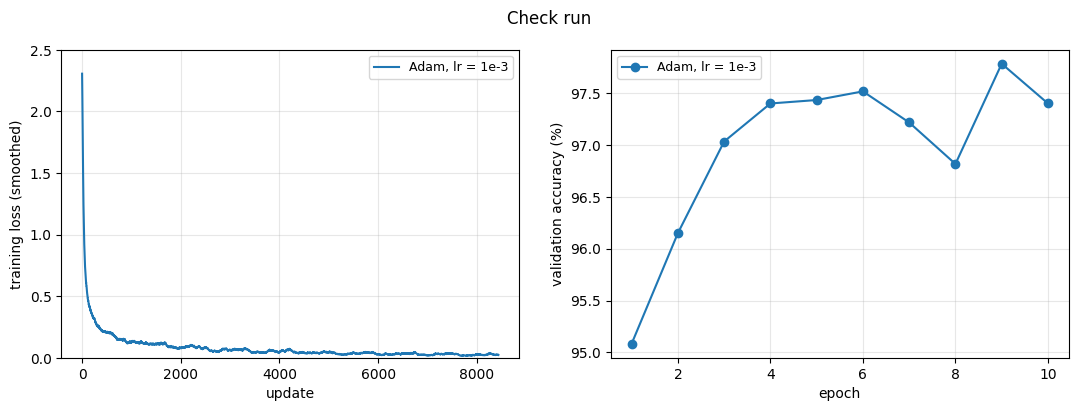

In [56]:
model = make_model(seed=0)
optimizer = optim.Adam(model.parameters(), lr=0.001)
hist = fit(model, optimizer, make_loader(batch_size=64, n_train=None), epochs=10)
plot_history({"Adam, lr = 1e-3": hist}, "Check run")

epoch  1 | lr 1.00e-01 | train loss 0.3066 | val loss 0.1598 | val acc 95.05% | 1.6 s
epoch  2 | lr 1.00e-01 | train loss 0.1169 | val loss 0.1095 | val acc 96.67% | 3.3 s
epoch  3 | lr 1.00e-01 | train loss 0.0820 | val loss 0.0984 | val acc 96.95% | 5.0 s
epoch  4 | lr 1.00e-01 | train loss 0.0594 | val loss 0.0945 | val acc 96.97% | 6.7 s
epoch  5 | lr 1.00e-01 | train loss 0.0465 | val loss 0.0845 | val acc 97.30% | 8.3 s
epoch  6 | lr 1.00e-01 | train loss 0.0357 | val loss 0.0929 | val acc 97.45% | 9.8 s
epoch  7 | lr 1.00e-01 | train loss 0.0273 | val loss 0.0848 | val acc 97.53% | 11.3 s
epoch  8 | lr 1.00e-01 | train loss 0.0220 | val loss 0.0878 | val acc 97.62% | 12.8 s
epoch  9 | lr 1.00e-01 | train loss 0.0166 | val loss 0.0936 | val acc 97.52% | 14.3 s
epoch 10 | lr 1.00e-01 | train loss 0.0114 | val loss 0.0804 | val acc 97.60% | 16.0 s


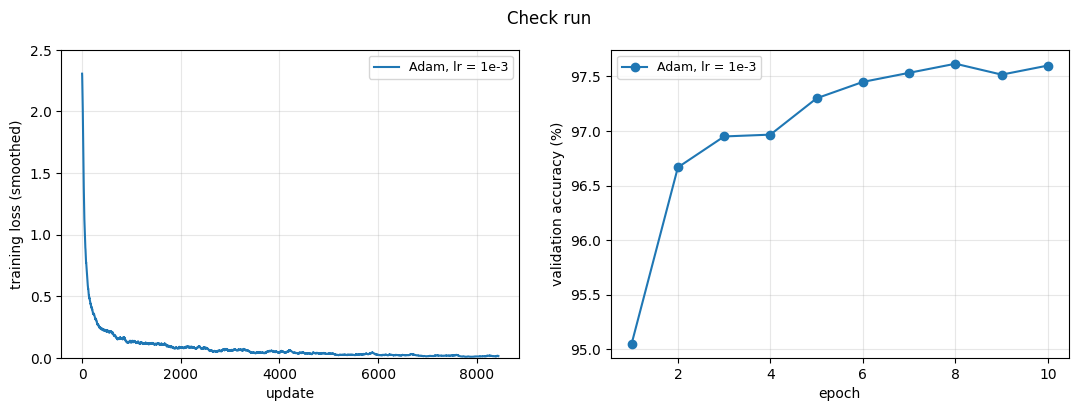

In [57]:
model = make_model(seed=0)
optimizer = optim.SGD(model.parameters(), lr=0.1)
hist = fit(model, optimizer, make_loader(batch_size=64, n_train=None), epochs=10)
plot_history({"Adam, lr = 1e-3": hist}, "Check run")

epoch  1 | lr 1.00e-01 | train loss 262.4336 | val loss 2.3613 | val acc 12.52% | 2.1 s
epoch  2 | lr 1.00e-01 | train loss 4.0392 | val loss 2.6357 | val acc 9.67% | 3.8 s
epoch  3 | lr 1.00e-01 | train loss 3.1509 | val loss 2.3837 | val acc 11.10% | 5.6 s
epoch  4 | lr 1.00e-01 | train loss 2.3282 | val loss 2.3652 | val acc 9.62% | 7.3 s
epoch  5 | lr 1.00e-01 | train loss 2.3118 | val loss 2.3656 | val acc 9.58% | 9.0 s
epoch  6 | lr 1.00e-01 | train loss 2.3109 | val loss 2.3592 | val acc 11.10% | 10.8 s
epoch  7 | lr 1.00e-01 | train loss 2.3110 | val loss 2.3650 | val acc 11.10% | 12.7 s
epoch  8 | lr 1.00e-01 | train loss 2.3115 | val loss 2.3591 | val acc 9.70% | 14.7 s
epoch  9 | lr 1.00e-01 | train loss 2.3113 | val loss 2.3578 | val acc 10.37% | 16.5 s
epoch 10 | lr 1.00e-01 | train loss 2.3112 | val loss 2.3616 | val acc 9.95% | 18.3 s


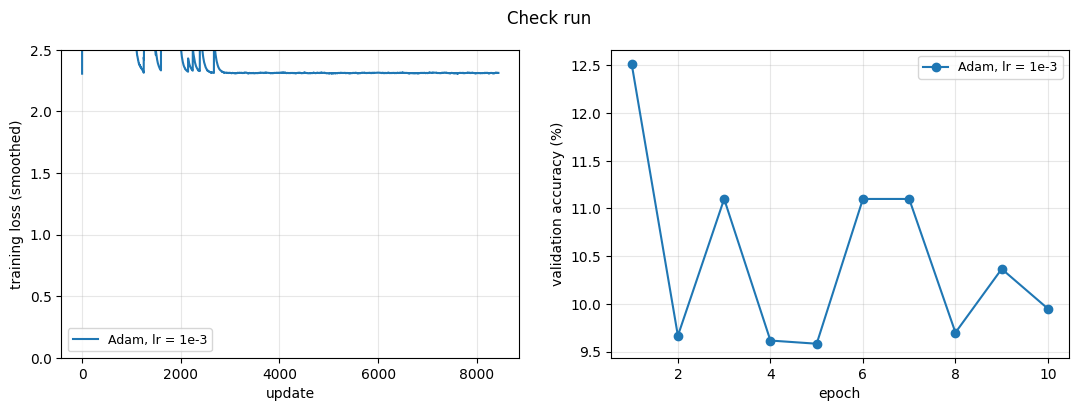

In [58]:
model = make_model(seed=0)
optimizer = optim.RMSprop(model.parameters(), lr=0.1)
hist = fit(model, optimizer, make_loader(batch_size=64, n_train=None), epochs=10)
plot_history({"Adam, lr = 1e-3": hist}, "Check run")

---
## ★ Exercises (to submit)

**Rules for all exercises**
- Train on the first **10,000** training examples (`make_loader(..., n_train=10_000)`) for **5 epochs**, unless the exercise says otherwise.
- Create every model with `make_model(seed=0)` (add `batch_norm=True` when asked), so that all runs start from the same weights.
- Use `fit`, `evaluate` and `plot_history` from Part 4. Choose everything on the **validation** set; use the test set only in Exercise 8.
- A run that diverges is a result too: report it.


### Exercise 1 · The learning rate of SGD
1. Train with `optim.SGD` (no momentum), batch size 64, for each $\alpha \in \{1, 0.3, 0.1, 0.03, 0.01, 0.001\}$.
2. Plot the six runs on one figure with `plot_history`.
3. Print the best validation accuracy of each run.

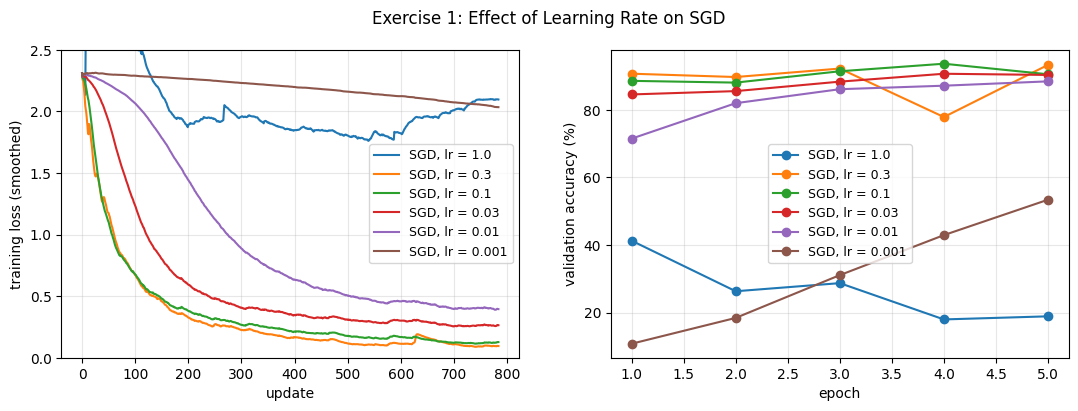

Learning Rate   | Best Val Acc | Final Train Loss |     Status
------------------------------------------------------------
          1.000 |       41.28% |           2.0679 |  Converged
          0.300 |       93.27% |           0.1064 |  Converged
          0.100 |       93.62% |           0.1164 |  Converged
          0.030 |       90.65% |           0.2572 |  Converged
          0.010 |       88.40% |           0.3938 |  Converged
          0.001 |       53.40% |           2.0486 |  Converged


In [59]:
# exercise 1: the learning rate of SGD
lrs_ex1 = [1.0, 0.3, 0.1, 0.03, 0.01, 0.001]
hists_ex1 = {}

for lr in lrs_ex1:
    m = make_model(seed=0)
    opt = optim.SGD(m.parameters(), lr=lr)
    label = f"SGD, lr = {lr}"
    hists_ex1[label] = fit(m, opt, make_loader(batch_size=64, n_train=10_000), epochs=5, verbose=False)

# plot all six runs
plot_history(hists_ex1, "Exercise 1: Effect of Learning Rate on SGD", ylim=(0, 2.5))

# print the best validation accuracy of each run
print(f"{'Learning Rate':15s} | {'Best Val Acc':>12s} | {'Final Train Loss':>16s} | {'Status':>10s}")
print("-" * 60)
for lr in lrs_ex1:
    label = f"SGD, lr = {lr}"
    h = hists_ex1[label]
    best_acc = max(h["val_acc"]) if h["val_acc"] else 0.0
    final_loss = h["train_loss"][-1] if h["train_loss"] else float('nan')
    status = "Diverged" if h["diverged"] else "Converged"
    print(f"{lr:15.3f} | {best_acc:11.2f}% | {final_loss:16.4f} | {status:>10s}")


**Exercise 1: your observations and explanation.** *Write here.*

### Exercise 2 · Batch size: one example, mini-batches, the full set
1. Train with `optim.SGD`, $\alpha = 0.01$, for **3 epochs**, with batch sizes 1, 32, 256 and 10,000 (10,000 = batch gradient descent on this training set).
2. For each run, print the number of updates per epoch, the time per epoch and the best validation accuracy.
3. Plot the four runs.
4. Repeat steps 1–3 with $\alpha = 0.1$.


===== Learning rate: 0.01 =====

Batch size: 1
Updates per epoch: 10000
Time per epoch: [13.47790508 13.46262837 13.55881922]
Best validation accuracy: 93.57%

Batch size: 32
Updates per epoch: 313
Time per epoch: [0.51060378 0.49667572 0.50645394]
Best validation accuracy: 88.87%

Batch size: 256
Updates per epoch: 40
Time per epoch: [0.11928825 0.12134854 0.12051356]
Best validation accuracy: 64.63%

Batch size: 10000
Updates per epoch: 1
Time per epoch: [0.0927332  0.07483367 0.076072  ]
Best validation accuracy: 9.80%


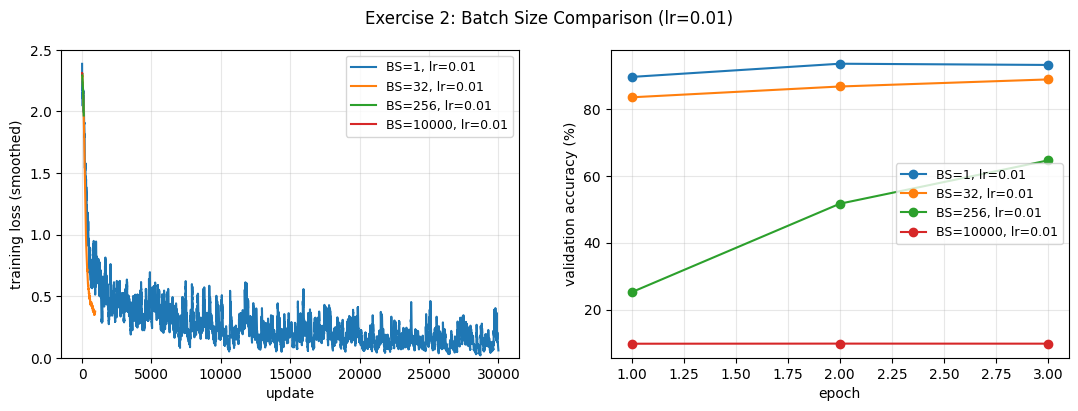


===== Learning rate: 0.1 =====
diverged (loss is nan or inf): stopping

Batch size: 1
Updates per epoch: 10000
Time per epoch: [13.78308139 12.71320723]
Best validation accuracy: 9.95%

Batch size: 32
Updates per epoch: 313
Time per epoch: [0.53945619 0.54281371 0.54003987]
Best validation accuracy: 93.57%

Batch size: 256
Updates per epoch: 40
Time per epoch: [0.1461872  0.12898675 0.12054154]
Best validation accuracy: 74.63%

Batch size: 10000
Updates per epoch: 1
Time per epoch: [0.08415209 0.36777638 0.08299528]
Best validation accuracy: 17.55%


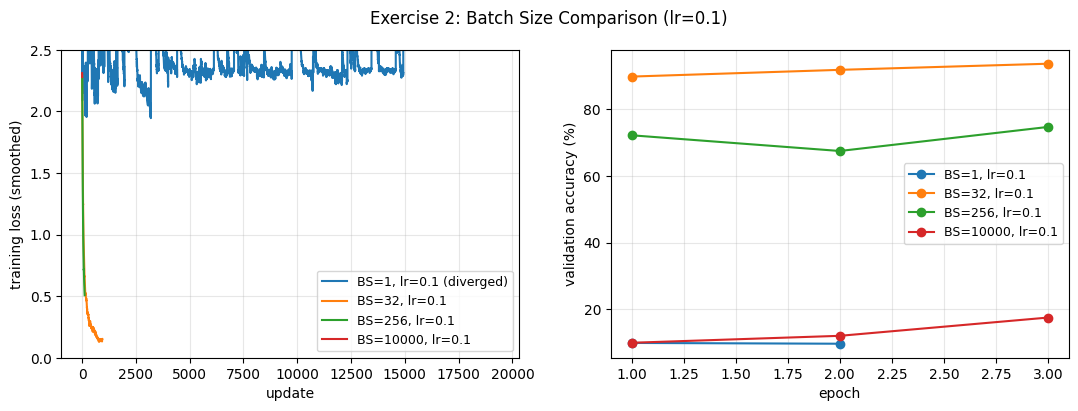

In [60]:
# Exercise 2
batch_sizes = [1, 32, 256, 10000]
learning_rates = [0.01, 0.1]

histories_ex2 = {}

for lr in learning_rates:
    print(f"\n===== Learning rate: {lr} =====")

    for bs in batch_sizes:
        model = make_model(seed=0)
        optimizer = optim.SGD(model.parameters(), lr=lr)

        loader = make_loader(batch_size=bs, n_train=10_000)

        hist = fit(model, optimizer, loader, epochs=3, verbose=False)

        label = f"BS={bs}, lr={lr}"
        histories_ex2[label] = hist

        updates = len(loader)
        epoch_times = np.diff([0] + hist["time"])

        best_acc = max(hist["val_acc"])

        print(f"\nBatch size: {bs}")
        print(f"Updates per epoch: {updates}")
        print(f"Time per epoch: {epoch_times}")
        print(f"Best validation accuracy: {best_acc:.2f}%")

    plot_history(
        {k: v for k, v in histories_ex2.items() if f"lr={lr}" in k},
        f"Exercise 2: Batch Size Comparison (lr={lr})"
    )


**Exercise 2: your observations and explanation.** *Write here.*

### Exercise 3 · Momentum
1. With batch size 64 and $\alpha = 0.01$, train: `optim.SGD(p, lr)`, `optim.SGD(p, lr, momentum=0.9)` and `optim.SGD(p, lr, momentum=0.9, nesterov=True)`.
2. Train `optim.SGD(p, lr=0.001, momentum=0.9)` and compare it with plain SGD at $\alpha = 0.01$.
3. Train `optim.SGD(p, lr, momentum=0.99)` with $\alpha = 0.01$.
4. Plot all the runs on one figure.

epoch  1 | lr 1.00e-02 | train loss 1.9640 | val loss 1.4242 | val acc 71.47% | 0.4 s
epoch  2 | lr 1.00e-02 | train loss 0.9640 | val loss 0.6974 | val acc 81.95% | 0.7 s
epoch  3 | lr 1.00e-02 | train loss 0.5692 | val loss 0.5124 | val acc 86.08% | 1.1 s
epoch  4 | lr 1.00e-02 | train loss 0.4508 | val loss 0.4438 | val acc 87.12% | 1.5 s
epoch  5 | lr 1.00e-02 | train loss 0.3938 | val loss 0.4040 | val acc 88.40% | 1.9 s
SGD lr=0.01                  best validation accuracy=88.40%
epoch  1 | lr 1.00e-02 | train loss 0.8135 | val loss 0.3554 | val acc 89.23% | 0.4 s
epoch  2 | lr 1.00e-02 | train loss 0.2945 | val loss 0.2834 | val acc 91.58% | 0.8 s
epoch  3 | lr 1.00e-02 | train loss 0.2109 | val loss 0.2458 | val acc 92.42% | 1.1 s
epoch  4 | lr 1.00e-02 | train loss 0.1593 | val loss 0.2065 | val acc 93.95% | 1.5 s
epoch  5 | lr 1.00e-02 | train loss 0.1195 | val loss 0.2028 | val acc 93.93% | 1.8 s
Momentum 0.9 lr=0.01         best validation accuracy=93.95%
epoch  1 | lr 1.00

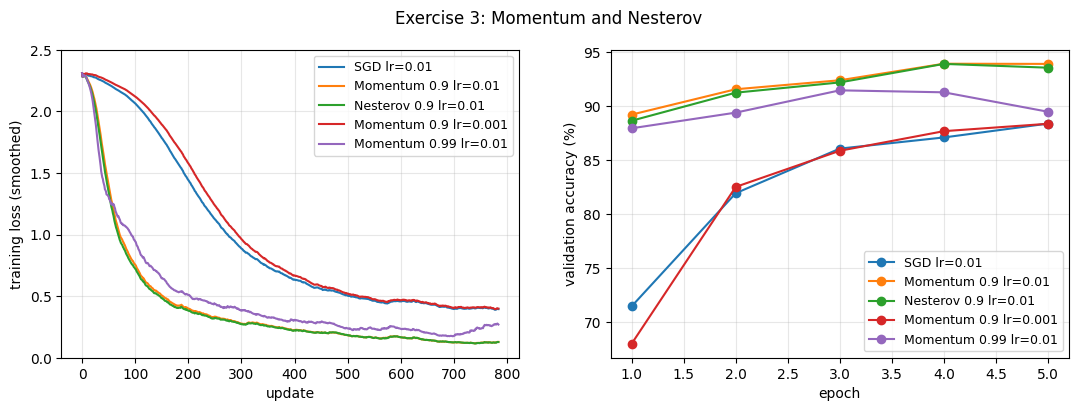

In [61]:
# Exercise 3  momentum and Nesterov
configs_e3 = [
    ("SGD lr=0.01", dict(lr=0.01, momentum=0.0, nesterov=False)),
    ("Momentum 0.9 lr=0.01", dict(lr=0.01, momentum=0.9, nesterov=False)),
    ("Nesterov 0.9 lr=0.01", dict(lr=0.01, momentum=0.9, nesterov=True)),
    ("Momentum 0.9 lr=0.001", dict(lr=0.001, momentum=0.9, nesterov=False)),
    ("Momentum 0.99 lr=0.01", dict(lr=0.01, momentum=0.99, nesterov=False)),
]
runs_e3 = {}
for label, cfg in configs_e3:
    model = make_model(seed=0)
    optimizer = optim.SGD(model.parameters(), **cfg)
    hist = fit(model, optimizer, make_loader(batch_size=64, n_train=10_000),
               epochs=5, verbose=True)
    runs_e3[label] = hist
    print(f"{label:28s} best validation accuracy={max(hist['val_acc']):.2f}%")
plot_history(runs_e3, "Exercise 3: Momentum and Nesterov", ylim=(0, 2.5))


**Exercise 3: your observations and explanation.** *Write here.*

### Exercise 4 · Optimizers and their learning rates
1. For each optimizer below, train with $\alpha \in \{10^{-1}, 10^{-2}, 10^{-3}, 10^{-4}\}$, batch size 64:
   `optim.SGD`, `optim.SGD(momentum=0.9)`, `optim.Adagrad`, `optim.RMSprop`, `optim.Adam`, `optim.AdamW`.
2. Show a table of the best validation accuracy: one row per optimizer, one column per learning rate.
3. Plot the best run of each optimizer on one figure.

\n===== SGD, lr=0.1 =====
epoch  1 | lr 1.00e-01 | train loss 0.7062 | val loss 0.3833 | val acc 88.55% | 0.3 s
epoch  2 | lr 1.00e-01 | train loss 0.2839 | val loss 0.3740 | val acc 88.03% | 0.6 s
epoch  3 | lr 1.00e-01 | train loss 0.2034 | val loss 0.2901 | val acc 91.38% | 1.0 s
epoch  4 | lr 1.00e-01 | train loss 0.1600 | val loss 0.2095 | val acc 93.62% | 1.3 s
epoch  5 | lr 1.00e-01 | train loss 0.1164 | val loss 0.3302 | val acc 90.50% | 1.6 s
Best validation accuracy: 93.62%
\n===== SGD, lr=0.01 =====
epoch  1 | lr 1.00e-02 | train loss 1.9640 | val loss 1.4242 | val acc 71.47% | 0.3 s
epoch  2 | lr 1.00e-02 | train loss 0.9640 | val loss 0.6974 | val acc 81.95% | 0.6 s
epoch  3 | lr 1.00e-02 | train loss 0.5692 | val loss 0.5124 | val acc 86.08% | 0.9 s
epoch  4 | lr 1.00e-02 | train loss 0.4508 | val loss 0.4438 | val acc 87.12% | 1.2 s
epoch  5 | lr 1.00e-02 | train loss 0.3938 | val loss 0.4040 | val acc 88.40% | 1.4 s
Best validation accuracy: 88.40%
\n===== SGD, lr=0.001

,lr=0.1,lr=0.01,lr=0.001,lr=0.0001
SGD,93.62,88.40,53.40,9.88
SGD + momentum,92.75,93.95,88.38,52.55
Adagrad,92.35,93.93,89.15,67.98
RMSprop,22.07,90.07,94.18,89.92
Adam,27.10,92.45,94.17,90.03
AdamW,36.60,92.78,94.02,90.05


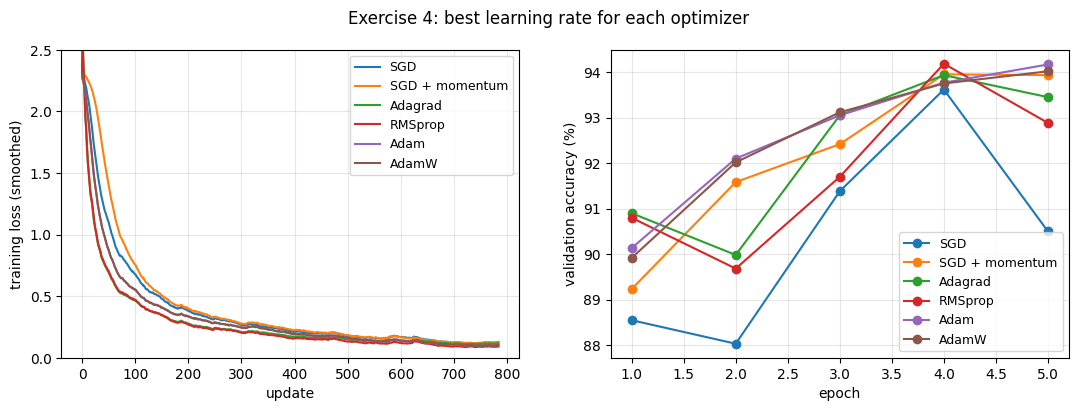

In [62]:
# Exercise 4
# Exercise 4 — optimizer × learning-rate sweep
lr_values_e4 = [1e-1, 1e-2, 1e-3, 1e-4]
optimizer_specs_e4 = {
    "SGD": lambda p, lr: optim.SGD(p, lr=lr),
    "SGD + momentum": lambda p, lr: optim.SGD(p, lr=lr, momentum=0.9),
    "Adagrad": lambda p, lr: optim.Adagrad(p, lr=lr),
    "RMSprop": lambda p, lr: optim.RMSprop(p, lr=lr),
    "Adam": lambda p, lr: optim.Adam(p, lr=lr),
    "AdamW": lambda p, lr: optim.AdamW(p, lr=lr),
}
results_e4 = {}
histories_e4 = {}
for opt_name, opt_fn in optimizer_specs_e4.items():
    results_e4[opt_name] = {}
    histories_e4[opt_name] = {}
    for lr in lr_values_e4:
        print(f"\\n===== {opt_name}, lr={lr:g} =====")
        model = make_model(seed=0)
        optimizer = opt_fn(model.parameters(), lr)
        hist = fit(model, optimizer, make_loader(batch_size=64, n_train=10_000),
                   epochs=5, verbose=True)
        best_acc = max(hist["val_acc"])
        results_e4[opt_name][lr] = best_acc
        histories_e4[opt_name][lr] = hist
        print(f"Best validation accuracy: {best_acc:.2f}%")

import pandas as pd
table_e4 = pd.DataFrame(results_e4).T
table_e4.columns = [f"lr={lr:g}" for lr in lr_values_e4]
display(table_e4.round(2))

best_runs_e4 = {}
for opt_name, row in table_e4.iterrows():
    best_lr = table_e4.loc[opt_name].idxmax()
    best_runs_e4[opt_name] = histories_e4[opt_name][float(best_lr.split("=")[1])]
plot_history(best_runs_e4, "Exercise 4: best learning rate for each optimizer", ylim=(0, 2.5))


**Exercise 4: your observations and explanation.** *Write here.*

### Exercise 5 · Learning rate schedules
1. With `optim.SGD(p, lr=0.05, momentum=0.9)` and batch size 64, train for **10 epochs** with:
   - a constant learning rate;
   - `optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.3)`;
   - `optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.7)`;
   - `optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=10)`;
   - `optim.lr_scheduler.StepLR(optimizer, step_size=1, gamma=0.1)` (decays too early).
2. Plot the learning rate of each run per epoch (from `history["lr"]`), with a log scale on the y-axis.
3. Plot the five runs with `plot_history(..., ylim=(0, 0.8))`.

=== constant 0.05 ===
best val acc 95.88% | final val acc 94.33% | final train loss 0.0446 | final val loss 0.3300
=== StepLR (step 3, gamma 0.3) ===
best val acc 95.80% | final val acc 95.78% | final train loss 0.0082 | final val loss 0.1773
=== ExponentialLR (gamma 0.7) ===
best val acc 95.58% | final val acc 95.53% | final train loss 0.0107 | final val loss 0.1783
=== CosineAnnealingLR (T_max 10) ===
best val acc 96.07% | final val acc 96.07% | final train loss 0.0026 | final val loss 0.1859
=== StepLR (step 1, gamma 0.1) ===
best val acc 93.70% | final val acc 93.70% | final train loss 0.1166 | final val loss 0.2120


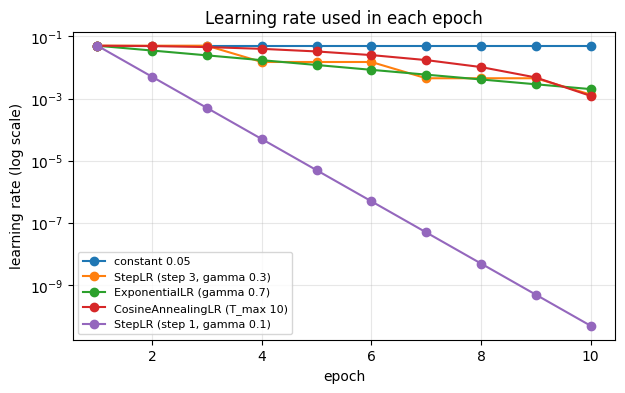

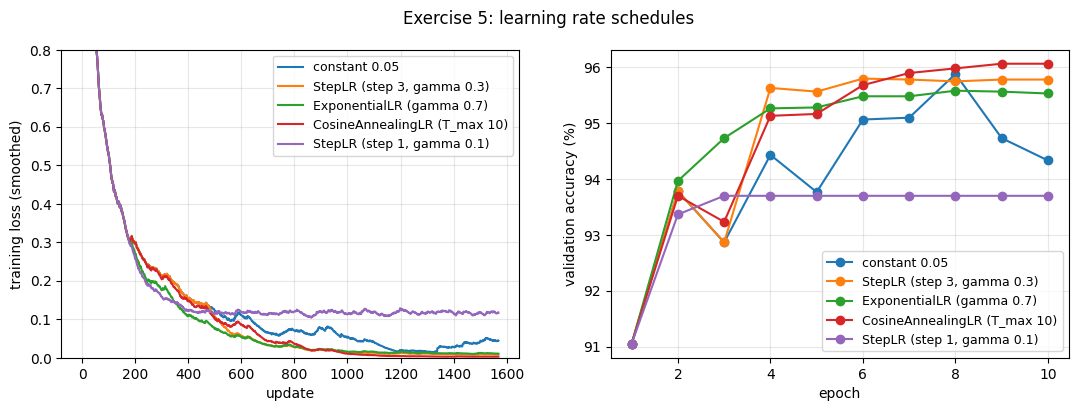


schedule                          lr first   lr last  best val acc  final train loss
constant 0.05                     5.00e-02  5.00e-02        95.88%            0.0446
StepLR (step 3, gamma 0.3)        5.00e-02  1.35e-03        95.80%            0.0082
ExponentialLR (gamma 0.7)         5.00e-02  2.02e-03        95.58%            0.0107
CosineAnnealingLR (T_max 10)      5.00e-02  1.22e-03        96.07%            0.0026
StepLR (step 1, gamma 0.1)        5.00e-02  5.00e-11        93.70%            0.1166


In [63]:
# Exercise 5

# Every run: SGD(lr=0.05, momentum=0.9), batch size 64, 10 epochs, first 10,000 training examples,
# same initial weights (make_model(seed=0)) and same mini-batch order (make_loader seed=0).
# Only the learning rate schedule changes.

EPOCHS = 10

# each entry: a function that takes the optimizer and returns a scheduler (None = constant lr)
schedules = {
    "constant 0.05":                  lambda opt: None,
    "StepLR (step 3, gamma 0.3)":     lambda opt: optim.lr_scheduler.StepLR(opt, step_size=3, gamma=0.3),
    "ExponentialLR (gamma 0.7)":      lambda opt: optim.lr_scheduler.ExponentialLR(opt, gamma=0.7),
    "CosineAnnealingLR (T_max 10)":   lambda opt: optim.lr_scheduler.CosineAnnealingLR(opt, T_max=10),
    "StepLR (step 1, gamma 0.1)":     lambda opt: optim.lr_scheduler.StepLR(opt, step_size=1, gamma=0.1),
}

hists5 = {}
for name, make_sched in schedules.items():
    print(f"=== {name} ===")
    model = make_model(seed=0)                                    # same initial weights for every run
    optimizer = optim.SGD(model.parameters(), lr=0.05, momentum=0.9)
    scheduler = make_sched(optimizer)                             # must be created AFTER the optimizer
    loader = make_loader(batch_size=64, n_train=10_000)           # same mini-batch order for every run
    hists5[name] = fit(model, optimizer, loader, epochs=EPOCHS, scheduler=scheduler, verbose=False)
    h = hists5[name]
    print(f"best val acc {max(h['val_acc']):.2f}% | final val acc {h['val_acc'][-1]:.2f}% | "
          f"final train loss {h['train_loss'][-1]:.4f} | final val loss {h['val_loss'][-1]:.4f}")

# 2. learning rate of each run, per epoch (log scale)
plt.figure(figsize=(7, 4))
for name, h in hists5.items():
    plt.plot(range(1, len(h["lr"]) + 1), h["lr"], "o-", label=name)
plt.yscale("log")
plt.xlabel("epoch"); plt.ylabel("learning rate (log scale)")
plt.title("Learning rate used in each epoch")
plt.grid(alpha=0.3, which="both"); plt.legend(fontsize=8); plt.show()

# 3. training loss (smoothed) and validation accuracy of the five runs
plot_history(hists5, "Exercise 5: learning rate schedules", ylim=(0, 0.8))

# summary table
print(f"\n{'schedule':32s} {'lr first':>9s} {'lr last':>9s} {'best val acc':>13s} {'final train loss':>17s}")
for name, h in hists5.items():
    print(f"{name:32s} {h['lr'][0]:9.2e} {h['lr'][-1]:9.2e} {max(h['val_acc']):12.2f}% {h['train_loss'][-1]:17.4f}")

**Exercise 5: your observations and explanation.** *Write here.*

**Exercise 5: your observations and explanation.** *Write here.*

### 1. What was done

Five runs were trained with exactly the same setup: the same initial weights (`make_model(seed=0)`), the same 10,000 training images in the same mini-batch order, SGD with momentum 0.9, batch size 64, initial learning rate $\alpha_0 = 0.05$, and 10 epochs (157 updates per epoch, 1,570 updates in total). **The only difference is the learning-rate schedule.** `fit` calls `scheduler.step()` once per epoch, so the learning rate is constant inside an epoch and changes only between epochs. `history["lr"]` records the rate used in each epoch.

This is a controlled experiment, and the figures confirm it. In epoch 1 all five runs use the same rate (0.05), and their training-loss curves are on top of each other until about update 157, and all five have exactly the same validation accuracy after epoch 1 (about 91.05%). The curves separate only when the schedules start to give different rates.

### 2. Why change the learning rate during training?

The learning rate $\alpha$ is the size of the step in $\theta \leftarrow \theta - \alpha \cdot (\text{update direction})$. A large and a small $\alpha$ have opposite advantages:

* **Large $\alpha$**: fast progress at the beginning, when the parameters are far from a good solution. But the gradient of a mini-batch is only a **noisy** estimate of the true gradient. With a large step, this noise moves the parameters randomly, so they keep bouncing around the minimum instead of settling in it (a "noise floor" that grows with $\alpha$).
* **Small $\alpha$**: precise steps that let the parameters settle in the bottom of the valley, but slow progress if used from the start.

A schedule combines both: **large first (move fast), small later (remove the noise)**. Here the optimizer uses momentum 0.9. The velocity adds up about $1/(1-0.9) = 10$ successive gradients, so the *effective* step is about $0.05 \times 10 = 0.5$. This is large, so we expect the constant run to be noisy.

### 3. The five schedules

With $t = 0, 1, \dots, 9$ the number of epochs already completed (epoch number = $t + 1$):

| Schedule | Formula | Learning rate in epochs 1, 2, ..., 10 |
|---|---|---|
| constant | $\alpha_t = 0.05$ | 0.05 in every epoch |
| StepLR (step 3, gamma 0.3) | $0.05 \cdot 0.3^{\lfloor t/3 \rfloor}$ | 0.05 (epochs 1-3), 0.015 (4-6), 0.0045 (7-9), 0.00135 (10) |
| ExponentialLR (gamma 0.7) | $0.05 \cdot 0.7^{t}$ | 0.05, 0.035, 0.0245, 0.0172, 0.0120, 0.0084, 0.0059, 0.0041, 0.0029, 0.0020 |
| CosineAnnealingLR (T_max 10) | $\frac{0.05}{2}\left(1 + \cos\frac{\pi t}{10}\right)$ | 0.050, 0.049, 0.045, 0.040, 0.033, 0.025, 0.017, 0.010, 0.0048, 0.0012 |
| StepLR (step 1, gamma 0.1) | $0.05 \cdot 0.1^{t}$ | 0.05, 0.005, 0.0005, $5\cdot10^{-5}$, ..., $5\cdot10^{-11}$ |

On the learning-rate figure (log scale) this is what we see: constant is a horizontal line. ExponentialLR and "step 1" are straight lines going down (a constant factor per epoch gives a straight line on a log axis), "step 1" much steeper (down to $10^{-10}$, far below the other curves). StepLR (step 3) is a staircase with two steps visible at epochs 4 and 7 (and a small one at epoch 10). Cosine stays near 0.05 for the first 3 epochs, then goes down faster, and ends close to the others at about $10^{-3}$.

### 4. Results

| Schedule | best val acc | final val acc | final train loss | final val loss |
|---|---|---|---|---|
| constant 0.05 | 95.88% | **94.33%** | 0.0446 | **0.3300** |
| StepLR (step 3, gamma 0.3) | 95.80% | 95.78% | 0.0082 | 0.1773 |
| ExponentialLR (gamma 0.7) | 95.58% | 95.53% | 0.0107 | 0.1783 |
| CosineAnnealingLR (T_max 10) | **96.07%** | **96.07%** | **0.0026** | 0.1859 |
| StepLR (step 1, gamma 0.1) | 93.70% | 93.70% | 0.1166 | 0.2120 |

### 5. Observations, run by run

1. **Constant 0.05: noisy and unstable at the end.** Its validation accuracy goes up and down: 94.4 → 93.8 → 95.05 → 95.1 → **95.88 (epoch 8)** → 94.7 → **94.33 (epoch 10)**. Its smoothed training loss reaches about 0.015 near update 1200, then **goes back up** to about 0.045 at the end, and its final validation loss (0.33) is almost twice that of the decayed runs (about 0.18). Its *best* accuracy (95.88%) is as high as the schedules', but it was reached by chance at epoch 8: one epoch later the accuracy has fallen by more than 1 point. Its *final* accuracy is the worst of the four runs that keep learning.
2. **StepLR (step 3, gamma 0.3).** It is identical to the constant run during epochs 1-3 (same rate), with the same dip at epoch 3 (about 92.9%). **Right after the first decay (epoch 4), the accuracy jumps to about 95.6%** and the training loss falls away from the constant curve (around update 470, the end of epoch 3). After that the curve is flat and stable (95.75-95.8%). Final: 95.78%.
3. **ExponentialLR (gamma 0.7).** Its rate decreases from the second epoch, so it is the best of the schedules in epochs 2-3 (93.97%, then 94.7%) and then rises smoothly with no dip. But it stops improving early (about 95.5% from epoch 6 on) and ends at 95.53% with a training loss (0.0107) higher than StepLR (step 3) and cosine.
4. **CosineAnnealingLR (T_max 10).** It keeps a high rate longer, so in the first epochs it is not better than the others (it also dips at epoch 3, to 93.25%). But its accuracy keeps **increasing steadily until the end** (95.7 → 95.9 → 96.0 → 96.07%) and it reaches the **best final accuracy and by far the lowest training loss (0.0026)**.
5. **StepLR (step 1, gamma 0.1): decays too early.** The rate is 10 times smaller after the first epoch. The accuracy still improves a little in epochs 2-3 (93.4% → 93.7%), then stays **exactly at 93.70% from epoch 3 to 10**, and the training loss is a **flat line at about 0.115** from about update 300. It finishes with the **lowest accuracy (93.70%) and a training loss (0.1166) 3 to 40 times higher than the other runs**.

### 6. Explanations

* **Why the constant run is unstable.** With an effective step of about 0.5, each update is dominated by the noise of its mini-batch. Near a minimum this noise pushes the parameters out of the valley again and again, so the loss and accuracy fluctuate: the model at the end of epoch 8 and the model at the end of epoch 10 are almost the same size of distance from the minimum, but one is lucky and one is not. This is why the training loss increases again after update 1300 and why the validation accuracy loses 1.5 points in two epochs. The best-accuracy number hides this problem, and the **final** accuracy and the validation loss show it.
* **Why decaying fixes it.** When $\alpha$ decreases, the random part of each step becomes smaller, so the parameters stop bouncing and move into the bottom of the valley. We see exactly this in the three good schedules: the loss goes *down again* after the rate drops (see the jump of StepLR (step 3) at epoch 4), the curves become smooth, and the accuracy stays at its level from one epoch to the next (the difference between best and final accuracy is at most 0.05 points, compared with 1.55 points for the constant run). This is the same problem seen in the follow-along with batch size 1, which reached the minimum region quickly but never settled and needed a decaying rate.
* **Why cosine reached the lowest training loss.** The total amount of learning rate used during the 10 epochs (the sum of the ten rates) is about **0.275 for cosine**, **0.210 for StepLR (step 3)** and **0.162 for ExponentialLR**. The order of the final training losses (0.0026 < 0.0082 < 0.0107) is the same. This is consistent with the following explanation: cosine keeps the large, fast rate for the first half of training (a lot of progress) and still ends with a very small rate (settling), while exponential decay lowers the rate from the very first epochs, so it has less total "travel" and its loss stops going down earlier (the plateau at 95.5% from epoch 6).
* **Why "step 1, gamma 0.1" is bad.** After epoch 1 the rate is 0.005, after epoch 3 it is 0.0005, and after epoch 4 it is below $10^{-4}$. Multiplying a gradient by such a small rate changes the parameters by almost nothing, so the model is **frozen** at the point it had reached after 2-3 epochs, which is far from converged: the training loss is still 0.115 while the other runs reach 0.003 to 0.04. This is **underfitting caused by the schedule**, not by the model or by lack of data. The last 7 epochs are wasted. The lesson: the decay must be matched to the total training time, so that the rate is still large in the first part of training and becomes small only near the end.
* **Loss and accuracy do not always agree.** Cosine has the lowest training loss (0.0026) and the best accuracy, but its validation loss (0.1859) is slightly higher than that of StepLR (step 3) and ExponentialLR (about 0.178). With only 10,000 training images all the decayed runs fit the training set almost perfectly (train loss $\ll$ val loss), so they are somewhat overconfident on the validation images they get wrong. The validation loss punishes wrong predictions made with high confidence; the accuracy only counts them. The differences here are small.

### 7. How much can we trust the differences?

The validation set has 6,000 images, so one image is 0.017 points of accuracy and the statistical uncertainty of one accuracy is about 0.25 points. Each setting was run **once**, with one seed. Therefore:

* The differences between **cosine (96.07%), StepLR step 3 (95.78%) and ExponentialLR (95.53%)** are only 0.3 to 0.5 points: they are **too small to say that one is truly better**. Cosine is the best in this run, but a different seed could change the order.
* The differences between these three and the **constant run (94.33% final, validation loss 0.33)**, and between them and **"step 1" (93.70%, training loss 0.117)**, are larger (1.2 to 2.4 points) and are supported by several signals at once (accuracy, losses, shape of the curves), so they are reliable.

### 8. Conclusion

A schedule changes neither the model nor the data, only how the optimizer moves. For SGD with momentum at $\alpha_0 = 0.05$, **starting with a large rate and decreasing it** gave a more stable, lower-loss and more accurate final model than keeping the rate constant (final accuracy 95.5-96.1% vs 94.3%, validation loss 0.18 vs 0.33), as long as the decay is **not too fast**: the schedule that divides the rate by 10 at every epoch froze the training after 3 epochs and gave the worst result (93.70%). Among the three good schedules, cosine annealing gave the best result in this run (96.07%), but the three are too close to rank them with certainty from one seed. Since the schedule is itself a hyperparameter (step size, gamma, T_max), it must be tuned on the validation set together with the initial learning rate, and in practice with several seeds.

### Exercise 6 · Batch normalization
1. For $\alpha \in \{1, 10^{-1}, 10^{-2}, 10^{-3}\}$, train `optim.SGD(p, lr, momentum=0.9)` with batch size 64, once **without** and once **with** batch norm (`make_model(seed=0, batch_norm=True)`).
2. Show a table of the best validation accuracy: rows = learning rates, columns = without / with batch norm.
3. Plot the eight runs.
4. Take your batch-norm model trained with $\alpha = 10^{-2}$. Evaluate it on the validation set in `model.eval()` mode (as `evaluate` does) and in `model.train()` mode with mini-batches of 8 examples, and compare the two accuracies.

In [64]:
# Exercise 6

**Exercise 6: your observations and explanation.** *Write here.*

### Exercise 7 · Your best model
1. Using what you learned in Exercises 1–6, choose an optimizer, a learning rate, a batch size, a schedule (or none), and with or without batch norm.
2. Train on the **full** training set (`n_train=None`) for 10 epochs.
3. Report the validation accuracy per epoch, and list your choices with one reason for each.

In [65]:
# Exercise 7

**Exercise 7: your observations and explanation.** *Write here.*

### Exercise 8 · Test accuracy
Evaluate your model of Exercise 7 on the test set, **once**, and report the test accuracy next to its best validation accuracy.

In [66]:
# Exercise 8

**Exercise 8: your observations and explanation.** *Write here.*

### Exercise 9 (optional) · CIFAR-10
CIFAR-10: 32 × 32 color images, 10 classes (airplane, car, bird, …), 50,000 training and 10,000 test images.
1. Load it with `datasets.CIFAR10(root="data", train=True, download=True)`. The images are in `.data`, a NumPy array of shape (50000, 32, 32, 3) with values 0–255; the labels are in `.targets`, a list.
2. Keep 45,000 images for training and 5,000 for validation. Normalize each of the 3 color channels with the mean and standard deviation of the training images, and flatten each image to a row of $32 \times 32 \times 3 = 3072$ values.
3. Replace `X_train, y_train, X_val, y_val` with the CIFAR-10 tensors, so that `make_loader`, `fit` and `evaluate` work unchanged, and create the models with `make_model(seed=0, n_in=3072, hidden=(512, 256), ...)`.
4. Train 10 epochs on the full CIFAR-10 training set with: (a) your configuration of Exercise 7, (b) the same without batch norm, (c) plain SGD with $\alpha = 0.01$. Plot the three runs.

In [67]:
# Exercise 9 (optional)

**Exercise 9: your observations and explanation.** *Write here.*

In [75]:
!git init
!git add .
!git commit -m "Initial commit"
!git branch -M main

Reinitialized existing Git repository in /content/.git/
Author identity unknown

*** Please tell me who you are.

Run

  git config --global user.email "you@example.com"
  git config --global user.name "Your Name"

to set your account's default identity.
Omit --global to set the identity only in this repository.

fatal: unable to auto-detect email address (got 'root@066a45653fe9.(none)')


In [84]:
!git add .
!git commit -m "Initial project upload"

Author identity unknown

*** Please tell me who you are.

Run

  git config --global user.email "you@example.com"
  git config --global user.name "Your Name"

to set your account's default identity.
Omit --global to set the identity only in this repository.

fatal: unable to auto-detect email address (got 'root@066a45653fe9.(none)')
